# M10-2 | 後端編譯器的視角：檢查 Q/DQ 圖是否滿足硬體約束

M10-1 的 `MyVPUQuantizer` 承諾會產生符合 VPU 約束的圖。但後端編譯器拿到的只有 `convert_pt2e` 的 Q/DQ 圖，不知道是哪個 quantizer 標的，也不該相信它。所以編譯器在吃圖之前要自己檢查一遍。

這本 notebook 寫一個只讀 Q/DQ 圖的檢查 pass `check_vpu`，規則對應 `vpu_quantizer.py` 的約束 (2)～(8)。約束 (1)（op 清單）不算違規：不在清單上的 op 切回 CPU，由 M10-3 處理。

- **A.** 七條規則：每條在 Q/DQ 圖上看什麼。
- **B.** 兩張 Q/DQ 圖過檢查：`MyVPUQuantizer` 的 vs torchao 測試版 XNNPACKQuantizer 的。
- **C.** 通過檢查換到什麼：每個 conv／linear 的 requant 倍率都是 $2^k$，硬體用 shift 就能做。

In [1]:
import torch
from torch.fx import Node

from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, quiet
from common.data import calibration_batches, trained_tiny_net
from common.models import example_inputs
from common.viz import draw, table
from vpu_quantizer import ADD, CAT, CONV2D, FLATTEN, LINEAR, MAX_POOL2D, RELU, fused_relu, vpu_ptq

quiet()
_ = torch.manual_seed(0)
QD = torch.ops.quantized_decomposed
Q_T, DQ_T, DQ_C = QD.quantize_per_tensor.default, QD.dequantize_per_tensor.default, QD.dequantize_per_channel.default
BATCH = 16

## A. 七條規則

| 規則 | 在 Q/DQ 圖上檢查什麼 | 對應約束 |
|---|---|---|
| R1 | 每個 `quantize_per_tensor`（activation）是 int8、zero point = 0 | (2) |
| R2 | 每個 `quantize_per_tensor` 與 weight 的 dequantize 的 scale 是 $2^k$ | (4) |
| R3 | add／cat／max_pool2d／flatten：輸入的 dq 與輸出的 q 是同一個 scale | (6) |
| R4 | conv／linear 的 bias 來自 int32 的 `dequantize_per_channel`，scale = $s_{in} \cdot s_w$ | (5) |
| R5 | relu 的輸入不是「conv／linear／add → q → dq」（中間不能有量化點） | (7) |
| R6 | placeholder 的 shape 沒有 SymInt | (8) |
| R7 | conv／linear 的 weight 來自 `dequantize_per_channel`，zero point 全 0、範圍 [-127, 127] | (3) |

檢查 pass 只讀 q/dq 的參數與連接關係，不看標籤（convert 之後標籤已經不重要了）。先寫兩個讀 scale 的小函式：

In [2]:
def scale_of(gm, n: Node) -> torch.Tensor:
    """q／dq node 的 scale：per-tensor 是寫在 args 裡的 float，per-channel 是 get_attr 指到的 buffer。"""
    s = n.args[1]
    if isinstance(s, Node):
        s = getattr(gm, str(s.target))
    return torch.as_tensor(s, dtype=torch.float64).flatten()


def is_pow2(s: torch.Tensor) -> bool:
    return bool(torch.all(torch.log2(s) == torch.round(torch.log2(s))))


def is_call(n, target) -> bool:
    return isinstance(n, Node) and n.op == "call_function" and n.target == target


def requant_inputs(gm, op: Node):
    """conv／linear 的 (s_in, s_w, s_out)；s_out 取自輸出（或融合的 relu）後面的 quantize_per_tensor。"""
    act, weight = op.args[0], op.args[1]
    assert isinstance(act, Node) and isinstance(weight, Node)
    out = fused_relu(op) or op
    q = next((u for u in out.users if is_call(u, Q_T)), None)
    return scale_of(gm, act), scale_of(gm, weight), (scale_of(gm, q) if q is not None else None)

檢查 pass 本身：逐一走過圖上的 node，每條規則幾行。

In [3]:
def check_vpu(gm):
    """只讀 Q/DQ 圖，回傳違規清單 [(規則, node 名稱, 說明)]。"""
    bad = []
    for n in gm.graph.nodes:
        if n.op == "placeholder":                                                     # R6
            val = n.meta.get("val")
            if isinstance(val, torch.Tensor) and not all(isinstance(d, int) for d in val.shape):
                bad.append(("R6", n.name, f"shape {tuple(val.shape)}"))
        if n.op != "call_function":
            continue
        if n.target == Q_T and (n.args[2] != 0 or n.args[5] != torch.int8):         # R1
            bad.append(("R1", n.name, f"zero point = {n.args[2]}"))
        if n.target in (Q_T, DQ_C) and not is_pow2(scale_of(gm, n)):                # R2
            bad.append(("R2", n.name, f"scale = {scale_of(gm, n)[0].item():.5g}"))
        if n.target in (ADD, CAT, MAX_POOL2D, FLATTEN):                               # R3
            ins = n.args[0] if n.target == CAT else (n.args[:2] if n.target == ADD else n.args[:1])
            assert isinstance(ins, (list, tuple))
            out = fused_relu(n) or n
            scales = {float(scale_of(gm, a)) for a in ins if is_call(a, DQ_T)}
            scales |= {float(scale_of(gm, q)) for q in out.users if is_call(q, Q_T)}
            if len(scales) > 1:
                bad.append(("R3", n.name, "scale = " + ", ".join(f"{s:.5g}" for s in sorted(scales))))
        if n.target in (CONV2D, LINEAR) and len(n.args) > 2 and isinstance(b := n.args[2], Node):   # R4
            if not (is_call(b, DQ_C) and b.args[-1] == torch.int32):
                bad.append(("R4", n.name, f"bias 來自 {b.op} node {b.name}（fp32）"))
            else:
                s_in, s_w, _ = requant_inputs(gm, n)
                if not torch.equal(scale_of(gm, b), s_in * s_w):
                    bad.append(("R4", n.name, "bias scale ≠ s_in × s_w"))
        if n.target in (CONV2D, LINEAR):
            w, zp = n.args[1], None
            assert isinstance(w, Node)
            if is_call(w, DQ_T) and not is_pow2(scale_of(gm, w)):                     # R2：per-tensor 的 weight
                bad.append(("R2", w.name, f"scale = {scale_of(gm, w)[0].item():.5g}"))
            if is_call(w, DQ_C) and isinstance(z := w.args[2], Node):
                zp = getattr(gm, str(z.target))
            if zp is None:                                                            # R7
                bad.append(("R7", n.name, f"weight 來自 {w.op} node {w.name}，不是 per-channel"))
            elif torch.any(zp != 0) or w.args[4:6] != (-127, 127):
                bad.append(("R7", n.name, f"範圍 {w.args[4:6]}，或 zero point 不是 0"))
        if n.target == RELU:                                                          # R5
            src = n.args[0]
            if is_call(src, DQ_T) and is_call(q := src.args[0], Q_T) and isinstance(op := q.args[0], Node) \
                    and op.target in (CONV2D, LINEAR, ADD):
                bad.append(("R5", n.name, f"{op.name} 與 relu 之間有 q/dq"))
    return bad

## B. 兩張 Q/DQ 圖過檢查

兩張圖都來自訓練好的 TinyConvNet、同一份校準資料：

- VPU 的圖：`vpu_ptq`（`vpu_quantizer.py`）= `torch.export.export(model, x)`（static shape）→ `prepare_pt2e(…, MyVPUQuantizer())` → 校準 → `convert_pt2e`。
- XNNPACK 的圖：`export_module` 的預設（動態 batch）→ `prepare_pt2e(…, torchao 測試版 XNNPACKQuantizer, per-channel)` → 校準 → `convert_pt2e`。

In [4]:
model, x = trained_tiny_net(), example_inputs(BATCH)
xnn_prepared = prepare_pt2e(export_module(model, x), get_xnnpack_quantizer(is_per_channel=True)[0])
with torch.no_grad():
    for b in calibration_batches(n=64, batch_size=BATCH):
        xnn_prepared(*b)
graphs = {"MyVPUQuantizer": vpu_ptq(model, x), "XNNPACKQuantizer": convert_pt2e(xnn_prepared)}
results = {name: check_vpu(g) for name, g in graphs.items()}
RULES = ["R1", "R2", "R3", "R4", "R5", "R6", "R7"]
table([[r] + [sum(v[0] == r for v in results[name]) for name in graphs] for r in RULES],
      ["規則"] + [f"{name} 的圖：違規數" for name in graphs])

規則,MyVPUQuantizer 的圖：違規數,XNNPACKQuantizer 的圖：違規數
R1,0,10
R2,0,16
R3,0,1
R4,0,5
R5,0,0
R6,0,1
R7,0,0


In [5]:
assert results["MyVPUQuantizer"] == []

`MyVPUQuantizer` 的圖 0 違規：M10-1 的每條約束都真的落實到 Q/DQ 圖上了。

XNNPACK 的圖，每條規則的第一筆違規：

In [6]:
WHY = {
    "R1": "activation spec 是 per_tensor_affine：zero point 跟著值域走，relu 之後是 -128",
    "R2": "用一般的 observer，scale 是任意浮點數",
    "R3": "add 的兩個輸入各自量化，沒有用 SharedQuantizationSpec（M03-4）",
    "R4": "不標 bias：bias 以 fp32 常數留在圖上，交給後端自己量化（M08、M09 的後端都這麼做）",
    "R5": "conv／add 和 relu 之間多了一組 q/dq",
    "R6": "這張圖用動態 batch export，而 XNNPACKQuantizer 的 validate() 不檢查 shape",
    "R7": "weight spec 不是 per-channel symmetric",
}
first = {}
for v in results["XNNPACKQuantizer"]:
    first.setdefault(v[0], v)
table([[r, node, detail, WHY[r]] for r, (_, node, detail) in sorted(first.items())], ["規則", "node", "看到的", "原因"])

規則,node,看到的,原因
R1,quantize_per_tensor_default_1,zero point = -128,activation spec 是 per_tensor_affine：zero point 跟著值域走，relu 之後是 -128
R2,dequantize_per_channel_default,scale = 0.0038905,用一般的 observer，scale 是任意浮點數
R3,add,"scale = 0.016419, 0.027519, 0.039895",add 的兩個輸入各自量化，沒有用 SharedQuantizationSpec（M03-4）
R4,conv2d,bias 來自 get_attr node stem_conv_weight_bias（fp32）,不標 bias：bias 以 fp32 常數留在圖上，交給後端自己量化（M08、M09 的後端都這麼做）
R6,x,"shape (s77, 3, 16, 16)",這張圖用動態 batch export，而 XNNPACKQuantizer 的 validate() 不檢查 shape


R3 畫出來看：`add` 的兩個輸入來自兩個 dequantize，scale 不同。

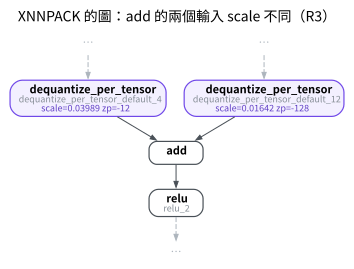

In [7]:
draw(graphs["XNNPACKQuantizer"], focus="add", hops=1, title="XNNPACK 的圖：add 的兩個輸入 scale 不同（R3）")

In [8]:
passed = [r for r in RULES if r not in first]
print("XNNPACK 的圖通過的規則：", passed)
assert passed == ["R5", "R7"]

XNNPACK 的圖通過的規則： ['R5', 'R7']


- R5 通過：XNNPACKQuantizer 也把 conv+relu、add+relu 當一個 pattern（M04-1）。
- R7 通過，是因為這裡傳了 `is_per_channel=True`；不傳的話 weight 是 per-tensor，這條就會違規。

XNNPACK 的圖在 CPU 上完全合理（M08 的 XNNPACK 就吃這種圖），只是不合這顆 VPU 的規格。同一張 Q/DQ 圖能不能部署，取決於後端；所以後端要附自己的 Quantizer，編譯器也要自己檢查。

## C. 通過檢查換到什麼：requant 倍率

整數 conv 的累加器是 int32，scale = $s_{in} \cdot s_w$；要寫回 int8（scale = $s_{out}$）得乘上

$$
M = \frac{s_{in} \cdot s_w}{s_{out}} \tag{1}
$$

從 VPU 的圖讀出每個 conv／linear 的三個 scale（weight 是 per-channel，列最小～最大）：

In [9]:
vpu = graphs["MyVPUQuantizer"]
rows, all_pow2 = [], True
for n in vpu.graph.nodes:
    if n.op != "call_function" or n.target not in (CONV2D, LINEAR):
        continue
    s_in, s_w, s_out = requant_inputs(vpu, n)
    assert s_out is not None
    m = s_in * s_w / s_out
    all_pow2 &= is_pow2(m)
    shift = (-torch.log2(m)).round().long()
    rows.append([n.name, f"2^{torch.log2(s_in).item():.0f}", f"2^{torch.log2(s_w).min():.0f}～2^{torch.log2(s_w).max():.0f}",
                 f"2^{torch.log2(s_out).item():.0f}", f"{shift.min().item()}～{shift.max().item()}"])
table(rows, ["node", "s_in", "s_w", "s_out", "右移位數（−log2 M）"])

node,s_in,s_w,s_out,右移位數（−log2 M）
conv2d,2^-5,2^-8～2^-7,2^-4,8～9
conv2d_1,2^-4,2^-9～2^-8,2^-4,8～9
conv2d_2,2^-4,2^-8～2^-7,2^-4,7～8
conv2d_3,2^-4,2^-9～2^-7,2^-4,7～9
linear,2^-5,2^-7～2^-6,2^-3,8～9


In [10]:
print("VPU 的圖：所有 M 都是 2^k：", all_pow2)
assert all_pow2
xnn = graphs["XNNPACKQuantizer"]
conv = next(n for n in xnn.graph.nodes if n.op == "call_function" and n.target == CONV2D)
s_in, s_w, s_out = requant_inputs(xnn, conv)
assert s_out is not None
m0 = (s_in * s_w / s_out)[0]
print(f"對照 XNNPACK 的圖：{conv.name} 第 0 個 channel 的 M = {m0.item():.6g}（log2 = {torch.log2(m0).item():.3f}）")

VPU 的圖：所有 M 都是 2^k： True
對照 XNNPACK 的圖：conv2d 第 0 個 channel 的 M = 0.00646425（log2 = -7.273）


VPU 圖的三個 scale 都由 Pow2 observer 決定，所以 $M$ 的指數就是三個指數相加減：累加器右移幾位就完成 requant。XNNPACK 圖的 $M$ 不是 2 的冪次，整數硬體一般要用「int32 乘數 + shift」的定點乘法做 requant（一般作法，本專案沒有實作）。

## 小結

- 檢查 pass 是後端那一側的防線：只讀 Q/DQ 圖上的 q/dq 參數與連接關係，就能判斷這張圖能不能上這顆 VPU。
- 每條規則都對應 `vpu_quantizer.py` 的一條約束；quantizer 沒做到時，這裡直接指出是哪個 node。
- 2 的冪次 scale 的好處變成具體的數字：每個 conv 的 requant 只是一個右移位數。